# 05 – Preprocessing and feature engineering

The model inputs are built from the training set only. 

- **raw**: product type and the five sensor variables
- **physics**: raw plus three physically motivated features
  - power = torque × angular speed [W]
  - temperature difference = process − air temperature [K]
  - strain = tool wear × torque [min·Nm]

The engineered features are row-wise calculations without fitted parameters, so they cannot leak information between rows. Scaling is fitted on data, so it is part of each model pipeline and is refitted on the training folds during cross-validation. Product type is one-hot encoded because the failure rates of L, M and H are not equally spaced. Identifiers and failure-mode flags are excluded (see notebook 02).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif

from config import FIG_DIR, SEED
from data import load_train_test
from features import build_features, make_preprocessor, FEATURE_SETS, PHYSICS_NUMERIC

train, _ = load_train_test()
X_train, y_train = build_features(train)
print(X_train.shape, y_train.shape)
X_train.head()

(6981, 9) (6981,)


,type,air_temp,process_temp,speed,torque,tool_wear,power,temp_diff,strain
0,M,298.1,308.6,1551,42.8,0,6951.590560,10.5,0.0
1,L,298.1,308.5,1498,49.4,5,7749.387543,10.4,247.0
2,L,298.2,308.6,1433,39.5,7,5927.504659,10.4,276.5
3,L,298.1,308.6,1558,42.4,14,6917.703247,10.5,593.6
4,M,298.3,308.7,1667,28.6,18,4992.639989,10.4,514.8


## 1. Engineered features

In [2]:
X_train[PHYSICS_NUMERIC].describe().round(2)

,power,temp_diff,strain
count,6981.00,6981.00,6981.00
mean,6271.40,9.99,4299.70
std,1070.29,1.00,2816.61
min,1264.05,7.60,0.00
25%,5557.60,9.20,1959.20
50%,6261.10,9.80,3991.10
75%,6994.44,11.00,6260.40
max,10233.15,12.10,14999.50


In [3]:
X_train[PHYSICS_NUMERIC].groupby(y_train.rename("failure")).median().round(2)

,power,temp_diff,strain
failure,,,
0,6233.95,9.8,3944.5
1,7733.30,9.2,7681.8


In [4]:
pd.Series({
    "Missing values": int(X_train.isna().sum().sum()),
    "Infinite values": int(np.isinf(X_train.drop(columns="type")).sum().sum()),
})

Missing values     0
Infinite values    0
dtype: int64

## 2. Preprocessing pipeline

The preprocessor is fitted on the full training set here only to inspect its output; in the models it is fitted inside each cross-validation fold.

In [5]:
for name in FEATURE_SETS:
    preprocessor = make_preprocessor(name)
    transformed = preprocessor.fit_transform(X_train)
    print(f"{name}: {transformed.shape[1]} columns -> {list(preprocessor.get_feature_names_out())}")

raw: 8 columns -> ['type_L', 'type_M', 'type_H', 'air_temp', 'process_temp', 'speed', 'torque', 'tool_wear']
physics: 11 columns -> ['type_L', 'type_M', 'type_H', 'air_temp', 'process_temp', 'speed', 'torque', 'tool_wear', 'power', 'temp_diff', 'strain']


In [6]:
inspect = make_preprocessor("physics").set_output(transform="pandas").fit_transform(X_train)
inspect.agg(["mean", "std"]).T.round(3) + 0.0

,mean,std
type_L,0.6,0.490
type_M,0.3,0.458
type_H,0.1,0.299
air_temp,0.0,1.000
process_temp,0.0,1.000
speed,0.0,1.000
torque,0.0,1.000
tool_wear,0.0,1.000
power,0.0,1.000
temp_diff,0.0,1.000


## 3. Information content of each feature

Mutual information measures how much knowing a feature reduces uncertainty about failure, including non-linear and threshold relationships that correlation misses. It is estimated on the training set and averaged over five random seeds to show its stability. It assesses each feature on its own, so it cannot show the value of combining features (e.g. HDF needs both temperature difference and speed).

In [7]:
numeric = FEATURE_SETS["physics"]
estimates = pd.DataFrame(
    {seed: mutual_info_classif(X_train[numeric], y_train, random_state=SEED + seed) for seed in range(5)},
    index=numeric,
)
mutual_info = pd.DataFrame({"mean": estimates.mean(axis=1), "std": estimates.std(axis=1)}).sort_values("mean")
mutual_info.sort_values("mean", ascending=False).round(4)

,mean,std
torque,0.0464,0.0007
power,0.0449,0.0001
speed,0.0395,0.0005
strain,0.0344,0.0001
tool_wear,0.0115,0.0006
temp_diff,0.0110,0.0022
air_temp,0.0066,0.0020
process_temp,0.0057,0.0019


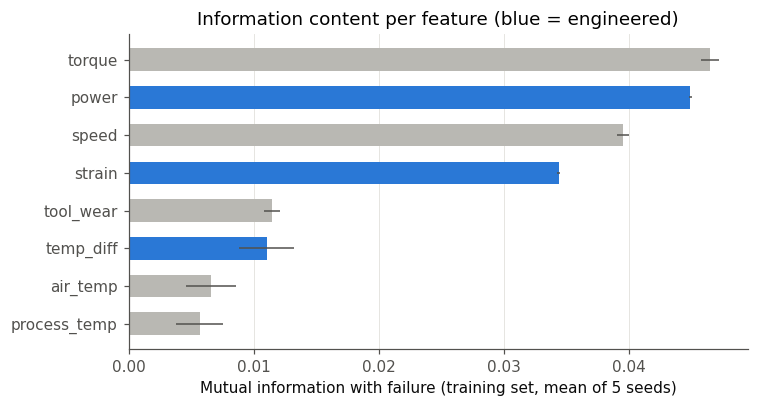

In [8]:
INK, MUTED, GRID, GRAY, BLUE = "#0b0b0b", "#52514e", "#e4e3df", "#b9b8b3", "#2a78d6"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
})

colors = [BLUE if name in PHYSICS_NUMERIC else GRAY for name in mutual_info.index]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(mutual_info.index, mutual_info["mean"], xerr=mutual_info["std"], color=colors, height=0.6,
        error_kw={"ecolor": MUTED, "elinewidth": 1})
ax.set_xlabel("Mutual information with failure (training set, mean of 5 seeds)")
ax.set_title("Information content per feature (blue = engineered)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_mutual_information.png")

Strain carries about three times more information than tool wear alone. The temperature difference carries somewhat more than either temperature, but its estimate is noisier and the margin is small. Power carries about as much information as torque alone, because torque and speed are already strongly coupled. Whether the engineered features improve the models is tested in notebook 07 (hypothesis H2).